In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [2]:
# 1. Define the Equations of Motion for the Hénon-Heiles Potential
def henon_heiles(t, q):
    x, y, vx, vy = q
    # Derivatives: d/dt [x, y, vx, vy] = [vx, vy, -dV/dx, -dV/dy]
    dxdt = vx
    dydt = vy
    dvxdt = -x - 2*x*y
    dvydt = -y - x**2 + y**2
    return [dxdt, dydt, dvxdt, dvydt]

In [3]:
# 2. Set up the Plane Crossing Event (Surface of Section at x = 0)
def x_crossing(t, q):
    return q[0]  # Returns x; the solver looks for when this equals 0

x_crossing.terminal = False
x_crossing.direction = 1  # Only register crossings moving from -x to +x (vx > 0)

In [4]:
# 3. Helper to build Initial Conditions keeping Total Energy (E) fixed
# E = 0.5*(vx^2 + vy^2) + 0.5*(x^2 + y^2) + x^2*y - (1/3)*y^3
def get_initial_conditions(y, vy, E):
    V = 0.5 * y**2 - (1.0/3.0) * y**3
    vx2 = 2.0 * (E - V) - vy**2
    if vx2 >= 0:
        return [0.0, y, np.sqrt(vx2), vy]  # Starts at x=0
    return None

In [5]:
# 4. Generate the Phase Space Plot
E = 0.13  # Energy level where order and chaos beautifully coexist
initial_points = [
    (0.0, 0.0),    # Bullseye center (Stable periodic orbit)
    (0.1, 0.0),    # regular concentric loop
    (0.3, 0.0),    # Outlying regular loop
    (0.2, 0.2),    # Secondary resonance island chain
    (-0.15, 0.35), # Outer resonance island
    (0.0, 0.45)    # Chaotic orbit (spreads out into a speckled sea)
]

plt.figure(figsize=(7, 7))

<Figure size 700x700 with 0 Axes>

<Figure size 700x700 with 0 Axes>

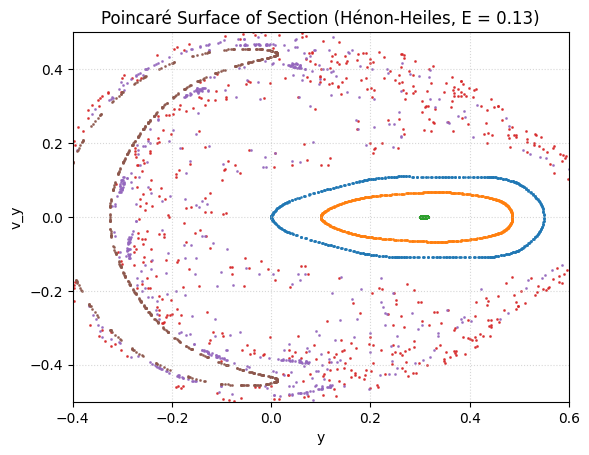

In [7]:
for y0, vy0 in initial_points:
    q0 = get_initial_conditions(y0, vy0, E)
    if q0 is None: continue
    
    # Integrate over a long time horizon to accumulate surface punctures
    sol = solve_ivp(henon_heiles, (0, 4000), q0, events=x_crossing, max_step=0.1, rtol=1e-8)
    
    if sol.y_events[0].size > 0:
        y_crossings = sol.y_events[0][:, 1]
        vy_crossings = sol.y_events[0][:, 3]
        plt.scatter(y_crossings, vy_crossings, s=1, alpha=0.8)

plt.title(f"Poincaré Surface of Section (Hénon-Heiles, E = {E})")
plt.xlabel("y")
plt.ylabel("v_y")
plt.xlim(-0.4, 0.6)
plt.ylim(-0.5, 0.5)
plt.grid(True, linestyle=":", alpha=0.5)
plt.show()